In [6]:
# load datasets and check columns
import pandas as pd

x_train = pd.read_csv("x_train_final.csv")
x_test = pd.read_csv("x_test_final.csv")

print("TRAIN COLUMNS:")
print(x_train.columns.tolist())

print("\nTEST COLUMNS:")
print(x_test.columns.tolist())

TRAIN COLUMNS:
['Unnamed: 0.1', 'Unnamed: 0', 'train', 'gare', 'date', 'arret', 'p2q0', 'p3q0', 'p4q0', 'p0q2', 'p0q3', 'p0q4']

TEST COLUMNS:
['Unnamed: 0', 'train', 'gare', 'date', 'arret', 'p2q0', 'p3q0', 'p4q0', 'p0q2', 'p0q3', 'p0q4']


In [7]:
# check unnamed col data
print(x_train[['Unnamed: 0.1', 'Unnamed: 0']].head(10))
print(x_test[['Unnamed: 0']].head(10))

   Unnamed: 0.1  Unnamed: 0
0             0           0
1             1           1
2             2           2
3             3           3
4             4           4
5             5           5
6             6           6
7             7           7
8             8           8
9             9           9
   Unnamed: 0
0           0
1           1
2           2
3           3
4           4
5           5
6           6
7           7
8           8
9           9


In [8]:
# drop unnamed col from both files
x_train = x_train.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])
x_test = x_test.drop(columns=['Unnamed: 0'])
print ("removed")

removed


In [10]:
# check data shape and col names 
print(x_train.shape)
print(x_test.shape)
print(x_train.columns.tolist())
print(x_test.columns.tolist())

(667264, 10)
(20657, 10)
['train', 'gare', 'date', 'arret', 'p2q0', 'p3q0', 'p4q0', 'p0q2', 'p0q3', 'p0q4']
['train', 'gare', 'date', 'arret', 'p2q0', 'p3q0', 'p4q0', 'p0q2', 'p0q3', 'p0q4']


In [11]:
# Load the target variable
y_train = pd.read_csv("y_train_final.csv")

# Check its structure
print("Shape:", y_train.shape)

print("\nFirst 10 values:")
print(y_train.head(10))

print("\nColumn names:")
print(y_train.columns.tolist())

Shape: (667264, 2)

First 10 values:
   Unnamed: 0  p0q0
0           0  -1.0
1           1  -1.0
2           2  -1.0
3           3   1.0
4           4   3.0
5           5  -2.0
6           6  -1.0
7           7  -1.0
8           8   2.0
9           9   0.0

Column names:
['Unnamed: 0', 'p0q0']


In [12]:
# remove unnamed col from target variable file
y_train = y_train.drop(columns=['Unnamed: 0'])
print("dropped")

In [14]:
# target file var names
print("\nColumn names:")
print(y_train.columns.tolist())


Column names:
['p0q0']


In [8]:
# Distribution of target value p0q0
print(y_train.describe())


#### the mean is affected by extreme 0.cuz it neg but the median is 0 meaning at least approximately 50% of observations are less than or equal to zero, 
        # and at least approximately 50% are greater than or equal to zero.
# the mean here means we have extreme negative values and the distribution has a neg tail

                p0q0
count  667264.000000
mean       -0.159950
std         1.987872
min      -160.000000
25%        -1.000000
50%         0.000000
75%         1.000000
max        15.000000


In [15]:
# target = y_train.iloc[:, 1] 
target = y_train['p0q0']

print("Negative values:", (target < 0).sum())
print("Zero values:", (target == 0).sum())
print("Positive values:", (target > 0).sum())

Negative values: 195761
Zero values: 284719
Positive values: 186784


In [16]:
print(y_train.head(20))
print(y_train.shape)
print(target.head())

    p0q0
0   -1.0
1   -1.0
2   -1.0
3    1.0
4    3.0
5   -2.0
6   -1.0
7   -1.0
8    2.0
9    0.0
10  -1.0
11   0.0
12   0.0
13   1.0
14  -1.0
15  -1.0
16   0.0
17   0.0
18   2.0
19   2.0
(667264, 1)
0   -1.0
1   -1.0
2   -1.0
3    1.0
4    3.0
Name: p0q0, dtype: float64


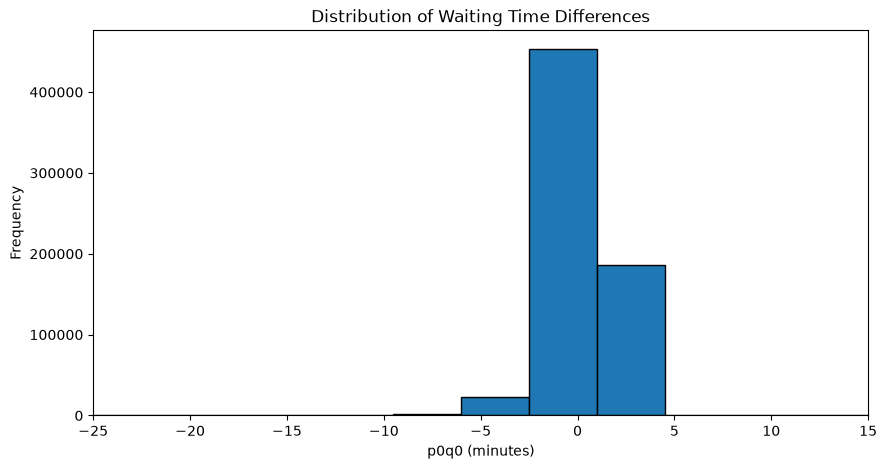

In [17]:
# Histogram zoomed range
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(target, bins=50, edgecolor='black')

# zooming in the range
plt.xlim(-25, 15) 

plt.title("Distribution of Waiting Time Differences")
plt.xlabel("p0q0 (minutes)")
plt.ylabel("Frequency")

plt.show()

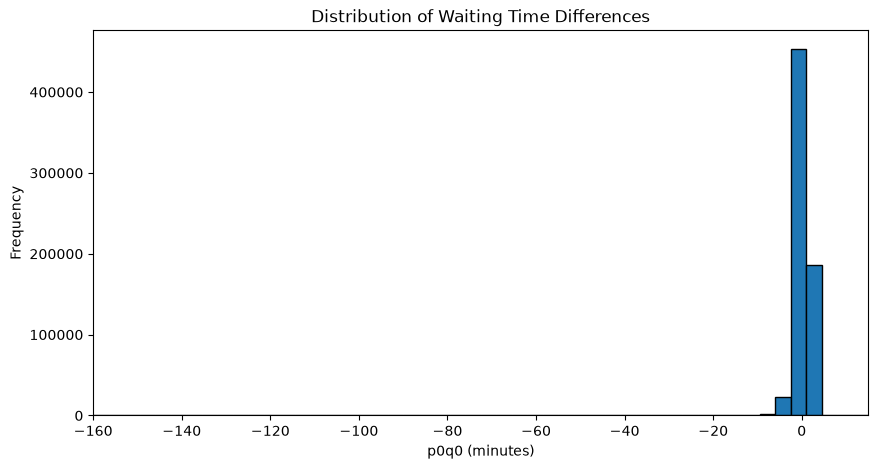

In [12]:
# Histogram full range

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(target, bins=50, edgecolor='black')

# zooming in the range
plt.xlim(-160, 15) 

plt.title("Distribution of Waiting Time Differences")
plt.xlabel("p0q0 (minutes)")
plt.ylabel("Frequency")

plt.show()

In [18]:
print(target.describe())

print("Minimum:", target.min())
print("Maximum:", target.max())
print("Median:", target.median())
print("Mean:", target.mean())

count    667264.000000
mean         -0.159950
std           1.987872
min        -160.000000
25%          -1.000000
50%           0.000000
75%           1.000000
max          15.000000
Name: p0q0, dtype: float64
Minimum: -160.0
Maximum: 15.0
Median: 0.0
Mean: -0.15995018463456742


In [19]:
# how many 160 values
print(target[target == -160].count())

1


In [20]:
# Unusual data 160
target[target == -160]

441542   -160.0
Name: p0q0, dtype: float64

In [21]:
x_train.loc[441542]
# train (k): train number (unique per day).
# gare (s): the station identifier.
# date (d): YYYY-MM-DD, the date the train runs.
# arret: stop number.

train        IZKJSK
gare            AZA
date     2023-09-14
arret            12
p2q0            1.0
p3q0           -2.0
p4q0            0.0
p0q2           -1.0
p0q3            0.0
p0q4            0.0
Name: 441542, dtype: object

In [22]:
# other observations for the same train on same date 
x_train.loc[
    (x_train['train'] == 'IZKJSK') &
    (x_train['date'] == '2023-09-14')
]

# 160 is same for the train 4 3 2 at the same station
# the value -160 might represent a real operational irregularity, or it might be a data-quality issue.

,train,gare,date,arret,p2q0,p3q0,p4q0,p0q2,p0q3,p0q4
441538,IZKJSK,KOG,2023-09-14,8,-1.0,-1.0,1.0,0.0,0.0,0.0
441539,IZKJSK,OML,2023-09-14,9,1.0,-1.0,-1.0,-1.0,-3.0,-2.0
441540,IZKJSK,GDU,2023-09-14,10,0.0,1.0,-1.0,1.0,1.0,1.0
441541,IZKJSK,XTD,2023-09-14,11,-2.0,0.0,1.0,1.0,3.0,1.0
441542,IZKJSK,AZA,2023-09-14,12,1.0,-2.0,0.0,-1.0,0.0,0.0
441543,IZKJSK,ZVY,2023-09-14,13,1.0,1.0,-2.0,-1.0,-1.0,-1.0
441544,IZKJSK,JBZ,2023-09-14,14,-160.0,1.0,1.0,1.0,1.0,2.0
441545,IZKJSK,RUP,2023-09-14,15,-157.0,-160.0,1.0,1.0,0.0,1.0
441546,IZKJSK,BAP,2023-09-14,16,2.0,-157.0,-160.0,0.0,0.0,-6.0
441547,IZKJSK,ZHN,2023-09-14,17,2.0,2.0,-157.0,0.0,-2.0,-4.0


In [23]:
# y data for the same train on same date
train_mask = (
    (x_train['train'] == 'IZKJSK') &
    (x_train['date'] == '2023-09-14')
)

print(y_train.loc[train_mask])

         p0q0
441538    0.0
441539   -2.0
441540    1.0
441541    1.0
441542 -160.0
441543 -157.0
441544    2.0
441545    2.0
441546    1.0
441547    2.0
441548    4.0
441549    2.0
441550    1.0
441551    3.0
441552    2.0
441553    3.0
441554    9.0
441555    3.0
441556    2.0
441557   -1.0


In [19]:
# no of values under and over 20 
print("Values below -20:", (target < -20).sum())

print("Values above 20:", (target > 20).sum())

Values below -20: 598
Values above 20: 0


In [29]:
# all under -15
extreme = target[target < -15]

print(extreme)

307      -25.0
308      -24.0
2750     -17.0
8102     -21.0
8531     -18.0
          ... 
667072   -52.0
667093   -55.0
667094   -58.0
667095   -60.0
667096   -61.0
Name: p0q0, Length: 951, dtype: float64


In [30]:
# extreme row values
extreme_rows = x_train.loc[extreme.index]

print(extreme_rows[['train', 'gare', 'date', 'arret']])

         train gare        date  arret
307     RLZGOP  HVA  2023-04-03     23
308     RLZGOP  RDU  2023-04-03     24
2750    IVPIYQ  LNI  2023-04-03     11
8102    PDEPFY  QYY  2023-04-04      8
8531    NNFXYB  AVF  2023-04-04     26
...        ...  ...         ...    ...
667072  SZSADB  KCK  2023-11-10     18
667093  SOVNXJ  UAK  2023-11-10     11
667094  SOVNXJ  ZFB  2023-11-10     12
667095  QYDSCZ  MRI  2023-11-10      8
667096  QYDSCZ  FFU  2023-11-10      9

[951 rows x 4 columns]


In [31]:
# # How extreme
extreme.describe()
# the median for all data was 0 but median for the extremes are -31 (the 50 percent data = median)

count    951.000000
mean     -31.301788
std       21.368998
min     -160.000000
25%      -35.000000
50%      -23.000000
75%      -19.000000
max      -16.000000
Name: p0q0, dtype: float64

In [32]:
# data count of extremes on dates
extreme_rows = x_train.loc[extreme.index]

print(extreme_rows['date'].value_counts().head(10))

# extreme observation are on clusters on certain dates

date
2023-11-10    74
2023-09-25    57
2023-09-14    53
2023-09-15    47
2023-10-11    44
2023-10-04    40
2023-09-19    27
2023-06-01    26
2023-09-28    24
2023-09-12    22
Name: count, dtype: int64


In [33]:
# extreme values on trains
print(extreme_rows['train'].value_counts().head(40))

train
UGPIHX    4
LXUQUT    4
XVRIRY    4
QNIPBI    4
KMZHHQ    3
LSJZZE    3
AOQITH    3
PEGKTX    3
YSWBBS    3
NEDHBC    3
MVGWPB    3
RLURBB    3
MDWINF    3
MEOTXR    3
BEZTNH    3
RZYZHZ    3
SGADSF    3
RLZGOP    2
NNFXYB    2
NTTXFS    2
SMNFKH    2
CMOZKY    2
DOXXZW    2
TQINIY    2
RCEVBX    2
XRYFGS    2
YHYZZY    2
LTWZSQ    2
FUCPSO    2
DYTNHN    2
PGUQQG    2
GDJUVF    2
PQADHV    2
NLCRYQ    2
LFUEUB    2
PRZIJW    2
UXNBBT    2
ARQXSY    2
OHDLLB    2
EVVMLH    2
Name: count, dtype: int64


In [34]:
# extreme counts on dates , trwins involved , stations involved
extreme_rows = x_train.loc[extreme.index].copy()

date_summary = (
    extreme_rows.groupby('date')
    .agg(
        extreme_count=('train', 'size'),
        unique_trains=('train', 'nunique'),
        unique_stations=('gare', 'nunique')
    )
    .sort_values('extreme_count', ascending=False)
)

print(date_summary.head(15))

# date specific railway disruption?
# systemetic err in data ?

            extreme_count  unique_trains  unique_stations
date                                                     
2023-11-10             74             36               32
2023-09-25             57             30               20
2023-09-14             53             28               27
2023-09-15             47             24               22
2023-10-11             44             24               18
2023-10-04             40             23               12
2023-09-19             27             16               12
2023-06-01             26             18               18
2023-09-28             24             14               15
2023-09-12             22             14               10
2023-06-09             21             13               15
2023-06-12             20             11               11
2023-06-13             20             12               12
2023-04-04             20             12               13
2023-06-06             20             12               11


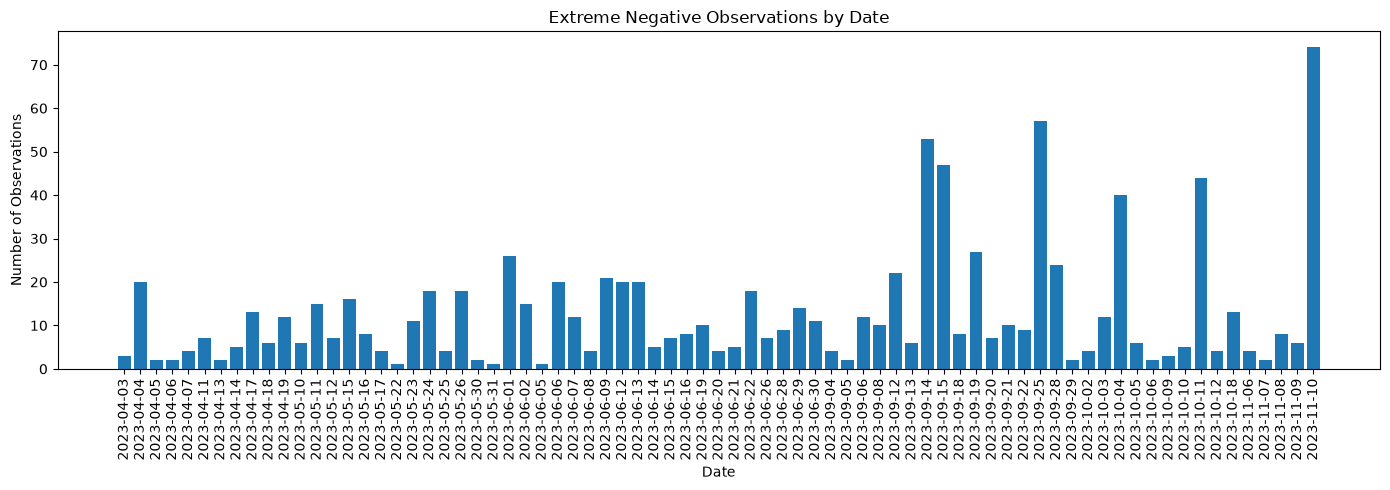

In [35]:
import matplotlib.pyplot as plt

date_counts = extreme_rows['date'].value_counts().sort_index()   ########

plt.figure(figsize=(14, 5))

plt.bar(date_counts.index, date_counts.values)

plt.title("Extreme Negative Observations by Date")
plt.xlabel("Date")
plt.ylabel("Number of Observations")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [36]:
daily_total = x_train.groupby('date').size()

daily_extreme = extreme_rows.groupby('date').size()

daily_comparison = pd.DataFrame({
    'total_observations': daily_total,
    'extreme_observations': daily_extreme
}).fillna(0)

daily_comparison['extreme_percentage'] = (
    daily_comparison['extreme_observations']
    / daily_comparison['total_observations'] * 100
)

print(
    daily_comparison
    .sort_values('extreme_percentage', ascending=False)
    .head(15)
)


# If many trains experienced unusual waiting times that day, the model might need to learn that certain patterns are associated with disruptions.

# This could be useful information for prediction.

# But there is another possibility: some extreme values could be caused by data collection or recording errors.

# need to distinguish between these possibilities.
# although 10 November has more extreme observations, it also has more total observations.

            total_observations  extreme_observations  extreme_percentage
date                                                                    
2023-11-10                7026                  74.0            1.053231
2023-09-14                5597                  53.0            0.946936
2023-09-25                7058                  57.0            0.807594
2023-09-15                7005                  47.0            0.670949
2023-10-11                8073                  44.0            0.545027
2023-10-04                7720                  40.0            0.518135
2023-09-19                7782                  27.0            0.346955
2023-06-01                8105                  26.0            0.320790
2023-06-06                6473                  20.0            0.308976
2023-09-28                7833                  24.0            0.306396
2023-09-12                7715                  22.0            0.285159
2023-06-09                7502                  21.

In [37]:
# extreme observations by station/ gare
# Get rows where the target is below -15
extreme_rows = x_train.loc[target < -15].copy()

# Count extreme observations by station
print(extreme_rows['gare'].value_counts().head(15))


# extreme values occur across multiple stations
# not obviously caused by one particular station or train.

gare
UYT    64
ZFB    57
OCB    56
VXY    55
KYF    48
ZHN    47
UAK    38
JYH    34
LNI    33
JLR    31
EOH    26
KCK    25
ZVY    22
OML    20
GDU    16
Name: count, dtype: int64


In [38]:
# Count extreme observations by train
print(extreme_rows['train'].value_counts().head(25))

# # extreme values occur across multiple trains
# not obviously caused by one particular station or train.

train
UGPIHX    4
LXUQUT    4
XVRIRY    4
QNIPBI    4
KMZHHQ    3
LSJZZE    3
AOQITH    3
PEGKTX    3
YSWBBS    3
NEDHBC    3
MVGWPB    3
RLURBB    3
MDWINF    3
MEOTXR    3
BEZTNH    3
RZYZHZ    3
SGADSF    3
RLZGOP    2
NNFXYB    2
NTTXFS    2
SMNFKH    2
CMOZKY    2
DOXXZW    2
TQINIY    2
RCEVBX    2
Name: count, dtype: int64


In [30]:
# Extreme values on dates 
extreme_rows['date'].value_counts().head(15)
# 14 and 15 September are consecutive dates with relatively high counts. This is worth investigating.

date
2023-11-10    60
2023-09-14    49
2023-09-15    38
2023-09-25    38
2023-10-11    38
2023-10-04    25
2023-09-19    20
2023-06-01    18
2023-05-15    16
2023-09-28    16
2023-06-22    15
2023-06-13    14
2023-10-18    13
2023-04-04    11
2023-06-06    11
Name: count, dtype: int64

# Three observations:
    # Extreme negative values occur across multiple trains.
    # They occur across multiple stations.
    # Some dates have noticeably more extreme observations than others.

In [39]:
# Extreme data on 10 th NOV

# Attach the target to the corresponding feature rows
check_data = x_train.copy()
check_data['p0q0'] = target.values

# Select extreme observations on 10 November
nov_extreme = check_data[
    (check_data['date'] == '2023-11-10') &
    (check_data['p0q0'] < -15)
]

print(nov_extreme.head(10))
print("Number of observations:", len(nov_extreme))
print("Target values:")
print(nov_extreme['p0q0'].value_counts().sort_index())

# Some observations have relatively normal historical features (values close to zero), but their target values are extremely negative.

# This means that the historical information doesn't always tell us that an extreme event is coming.

# few possibilities:
    #Operational disruptions: Something unusual happened on that date, affecting train waiting times.
    #Unexpected events: Some trains experienced unusual waiting-time differences that were not reflected in their previous observations.
    #Data-quality issues: Some records may contain incorrect or inconsistent values.

         train gare        date  arret  p2q0  p3q0  p4q0  p0q2  p0q3  p0q4  \
663549  MSFTXL  VXY  2023-11-10     15 -13.0   0.0   0.0  -5.0  -1.0  -1.0   
663550  MSFTXL  KCK  2023-11-10     16 -14.0 -13.0   0.0  -5.0  -2.0  -8.0   
663559  DKLAEO  ZFB  2023-11-10     14   0.0   1.0   1.0 -12.0 -32.0  -5.0   
663565  WYCIAP  JYH  2023-11-10      8   1.0   1.0   0.0   1.0   1.0   1.0   
663566  WYCIAP  UYT  2023-11-10      9   1.0   1.0   1.0 -10.0   2.0   0.0   
663837  BRDDGD  AVU  2023-11-10     23  -9.0  -9.0  -5.0   1.0   2.0  -3.0   
663838  BRDDGD  AVF  2023-11-10     24  -2.0  -9.0  -9.0   1.0   2.0  -8.0   
663849  UBCWEN  RUP  2023-11-10     15   1.0  -1.0   0.0   1.0 -10.0  -5.0   
663850  UBCWEN  BAP  2023-11-10     16  -1.0   1.0  -1.0 -10.0  -5.0  -9.0   
663863  KTVPGS  ZHN  2023-11-10     17   1.0   1.0   1.0   1.0 -19.0  -1.0   

        p0q0  
663549 -84.0  
663550 -93.0  
663559 -29.0  
663565 -26.0  
663566 -27.0  
663837 -74.0  
663838 -74.0  
663849 -66.0  
663850

In [40]:
# extreme values in Nov by station/ gare
nov_extreme['gare'].value_counts()

gare
KYF    11
ZHN     9
ZFB     6
UYT     5
AVF     4
AVU     3
VXY     2
KCK     2
RUP     2
BAP     2
LNI     2
ELZ     2
UAK     2
HVA     2
JLR     2
JBZ     2
JYH     1
MZE     1
OJA     1
XEH     1
ZAL     1
GHQ     1
EOH     1
ZVY     1
XTD     1
AZA     1
OCB     1
EAU     1
KLN     1
QYY     1
MRI     1
FFU     1
Name: count, dtype: int64

In [34]:
# extreme values in NOV by grouped by gare / station with their distribution min , max, mean for P0q0
nov_extreme.groupby('gare')['p0q0'].agg(
    ['count', 'mean', 'min', 'max']
).sort_values('count', ascending=False)


# some stations appear multiple times in the extreme observations.
# worth investing cuz the extreme values are not all coming from completely different stations.


# some stations have particularly negative average values among their extreme observations.
# like ELZ has only two observations, but both are between -77 and -79.
# as the sample size is small (2), We should not assume ELZ generally experiences such large differences.

,count,mean,min,max
gare,,,,
KYF,6,-66.500000,-81.0,-29.0
ZFB,6,-57.333333,-82.0,-29.0
UYT,5,-48.400000,-80.0,-24.0
ZHN,5,-67.800000,-86.0,-23.0
AVF,4,-67.250000,-87.0,-36.0
AVU,3,-64.000000,-75.0,-43.0
UAK,2,-62.500000,-70.0,-55.0
LNI,2,-56.000000,-79.0,-33.0
RUP,2,-65.000000,-66.0,-64.0


# Analyzing the historical values


In [41]:
# normal vs extreme values according to historical data groups
features = ['p2q0', 'p3q0', 'p4q0',
            'p0q2', 'p0q3', 'p0q4']

check_data = x_train.copy()
check_data['p0q0'] = target.values

check_data['target_group'] = 'Normal'
check_data.loc[check_data['p0q0'] < -15, 'target_group'] = 'Extreme'

comparison = check_data.groupby('target_group')[features].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(comparison.T)

# Extreme current waiting-time differences.
# Extreme historical waiting-time differences.

target_group     Extreme         Normal
p2q0 count    951.000000  666313.000000
     mean      -1.610936      -0.168640
     median     0.000000       0.000000
     min      -96.000000    -160.000000
     max       13.000000      14.000000
p3q0 count    951.000000  666313.000000
     mean      -0.923239      -0.166225
     median     0.000000       0.000000
     min      -48.000000    -160.000000
     max        4.000000      15.000000
p4q0 count    951.000000  666313.000000
     mean      -0.667718      -0.175607
     median     0.000000       0.000000
     min      -43.000000    -160.000000
     max        7.000000      15.000000
p0q2 count    951.000000  666313.000000
     mean      -6.970557      -0.153507
     median    -1.000000       0.000000
     min     -126.000000    -160.000000
     max       12.000000      15.000000
p0q3 count    951.000000  666313.000000
     mean      -4.378549      -0.167577
     median     0.000000       0.000000
     min      -81.000000   -1441.000000


In [37]:
# p0q3  -1441
check_data.loc[
    check_data['p0q3'] == -1441,
    ['train', 'gare', 'date', 'arret',
     'p0q0', 'p0q2', 'p0q3', 'p0q4']
].head(20)

,train,gare,date,arret,p0q0,p0q2,p0q3,p0q4
315111,JXNGKF,VXY,2023-06-21,21,-3.0,-2.0,-1441.0,0.0


In [42]:
# Count extreme historical values
for feature in features:
    print(
        feature,
        (check_data[feature] < -15).sum()
    )


    # historical extreme values genuine operational observations, or caused by data-quality problems?

p2q0 891
p3q0 849
p4q0 812
p0q2 939
p0q3 913
p0q4 923


In [43]:
#  Extreme target vs extreme feature values and their overlaps 
for feature in features:

    overlap = (
        (check_data['p0q0'] < -15) &
        (check_data[feature] < -15)
    ).sum()

    print(f"{feature}:")
    print("Extreme target:", (check_data['p0q0'] < -15).sum())
    print("Extreme feature:", (check_data[feature] < -15).sum())
    print("Both extreme:", overlap)
    print()

# Extreme negative waiting-time differences at previous stations of the same train coincide more frequently with extreme negative target values
    #than extreme differences from previous trains at the same station.

p2q0:
Extreme target: 951
Extreme feature: 891
Both extreme: 21

p3q0:
Extreme target: 951
Extreme feature: 849
Both extreme: 6

p4q0:
Extreme target: 951
Extreme feature: 812
Both extreme: 2

p0q2:
Extreme target: 951
Extreme feature: 939
Both extreme: 158

p0q3:
Extreme target: 951
Extreme feature: 913
Both extreme: 95

p0q4:
Extreme target: 951
Extreme feature: 923
Both extreme: 80



### Extreme negative waiting-time differences at previous stations of the same train coincide more frequently with extreme negative target values than extreme differences from previous trains at the same station.

In [40]:
# correlation of p0q0 with other historical values 
correlation = check_data[features + ['p0q0']].corr()

print(correlation['p0q0'].sort_values(ascending=False))

# Historical information from the current train's previous stations appears more strongly associated with the target.
# The second previous station (p0q2) has the strongest correlation.
# The relationship weakens for older stations.
# Previous trains at the current station have very weak individual linear correlations with the target.

p0q0    1.000000
p0q2    0.277717
p0q3    0.156384
p0q4    0.085419
p4q0    0.039447
p3q0    0.025357
p2q0   -0.052890
Name: p0q0, dtype: float64


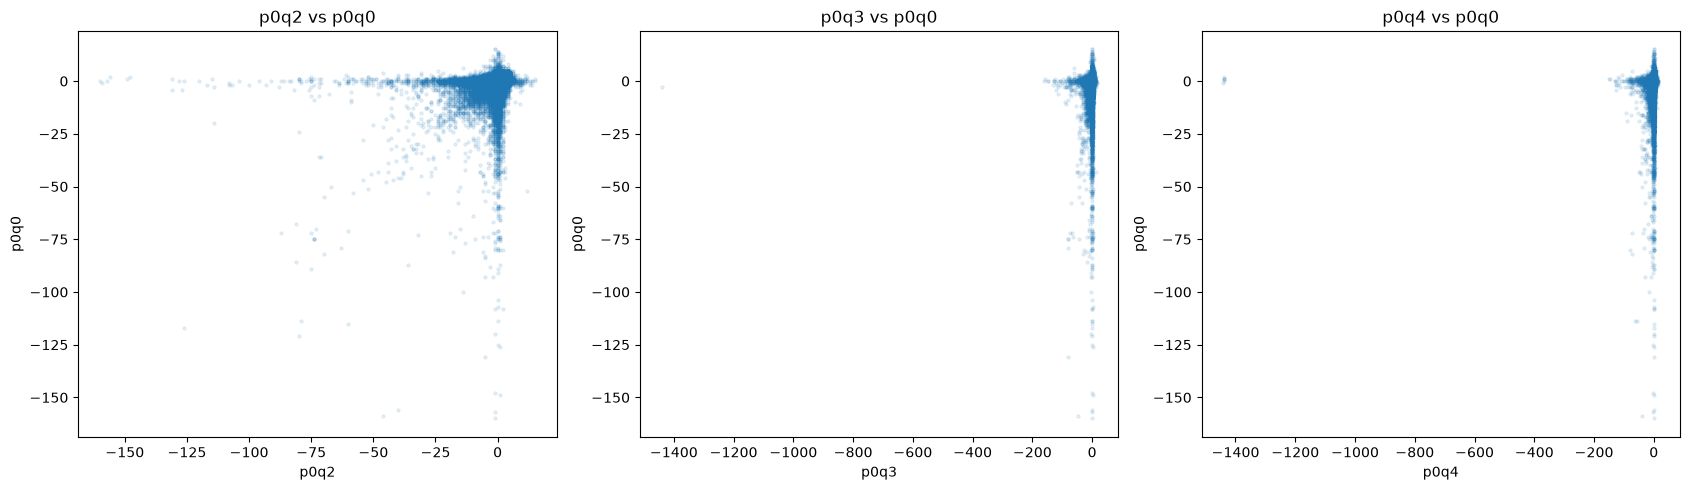

In [41]:
# plot for p0q0 vs earlier train stations (correlation)
# matplotlib.pyplot as plt

features_to_plot = ['p0q2', 'p0q3', 'p0q4']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for feature, ax in zip(features_to_plot, axes):

    ax.scatter(
        check_data[feature],
        check_data['p0q0'],
        alpha=0.1,
        s=5
    )

    ax.set_title(f'{feature} vs p0q0')
    ax.set_xlabel(feature)
    ax.set_ylabel('p0q0')

plt.tight_layout()
plt.show()

# values are concentrated around 0.
# p0q2 shows a slightly pos relation with the diagonal line meaning with increasining p0q2 , p0q0 also increases

In [44]:
# p0q2 and p0q0, 0 vs non 0 data
nonzero_data = check_data[
    (check_data['p0q0'] != 0) &
    (check_data['p0q2'] != 0)
]

print("Original observations:", len(check_data))
print("Non-zero observations:", len(nonzero_data))

print(
    nonzero_data[['p0q2', 'p0q0']].corr()
)

# prev with all data the corr was .2777
# now with only non 0 its increased to .380 for p0q2 and p0q0

Original observations: 667264
Non-zero observations: 241073
          p0q2      p0q0
p0q2  1.000000  0.380788
p0q0  0.380788  1.000000


In [45]:
# non zero correlation for all features
nonzero_correlations = {}

for feature in features:

    nonzero_data = check_data[
        (check_data['p0q0'] != 0) &
        (check_data[feature] != 0)
    ]

    corr = nonzero_data[feature].corr(
        nonzero_data['p0q0']
    )

    nonzero_correlations[feature] = {
        'observations': len(nonzero_data),
        'correlation': corr
    }

print(pd.DataFrame(nonzero_correlations).T)

# previous trains' waiting-time differences at the same station have only a weak linear relationship with the current target.
# current train's waiting-time differences at its previous stations are more strongly associated with its waiting-time difference at the current station.
# the relationship gets weaker as we move further back through the train's previous stops.

      observations  correlation
p2q0      233162.0    -0.076115
p3q0      223009.0     0.040254
p4q0      227675.0     0.060499
p0q2      241073.0     0.380788
p0q3      234876.0     0.201573
p0q4      241199.0     0.112828


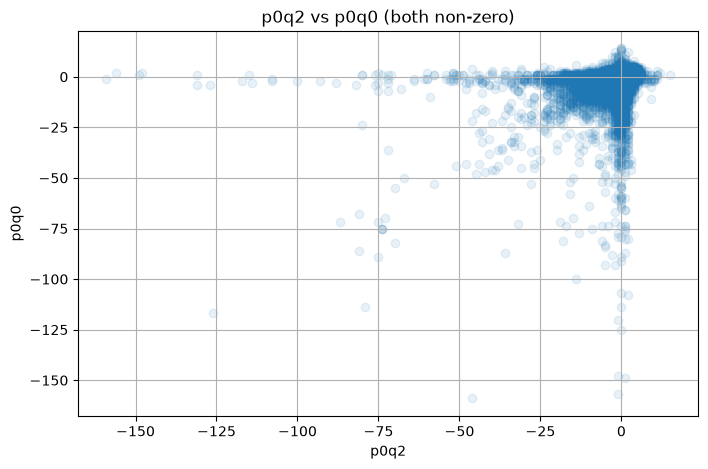

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    nonzero_data['p0q2'],
    nonzero_data['p0q0'],
    alpha=0.1
)

plt.xlabel('p0q2')
plt.ylabel('p0q0')
plt.title('p0q2 vs p0q0 (both non-zero)')
plt.grid()
plt.show()

# we can see a slighly diagonal lone meaning a pos relationship between p0q2 and p0q0

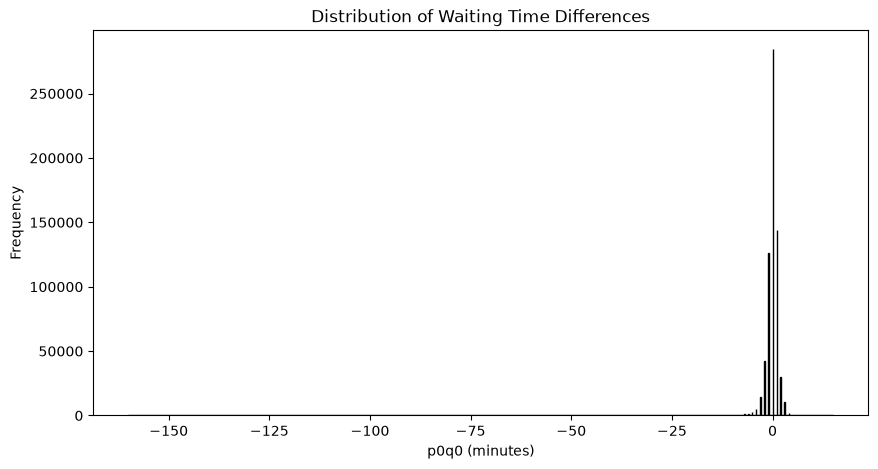

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Freedman–Diaconis
plt.hist(target, bins='fd', edgecolor='black')

plt.title("Distribution of Waiting Time Differences")
plt.xlabel("p0q0 (minutes)")
plt.ylabel("Frequency")

plt.show()

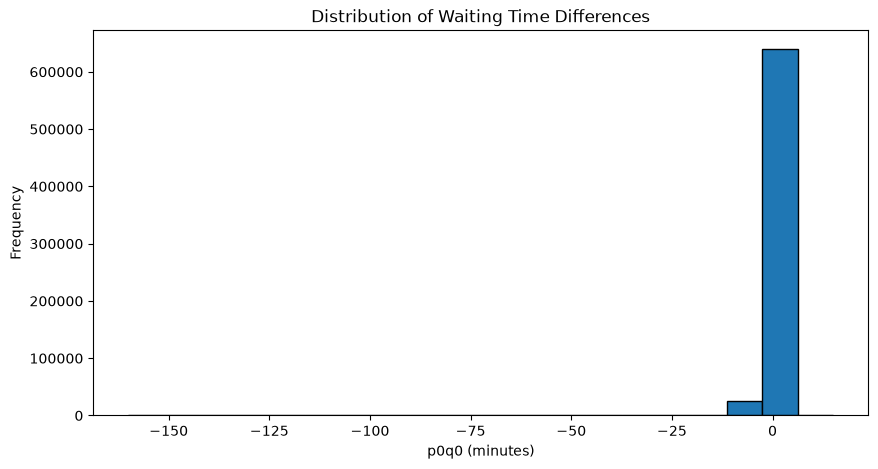

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(target, bins=20, edgecolor='black')

plt.title("Distribution of Waiting Time Differences")
plt.xlabel("p0q0 (minutes)")
plt.ylabel("Frequency")

plt.show()

In [47]:
print(check_data['date'].dtype)
print(check_data['date'].head())

str
0    2023-04-03
1    2023-04-03
2    2023-04-03
3    2023-04-03
4    2023-04-03
Name: date, dtype: str
